# Basics of spin dynamics with `spin::Qudit`

The C++ class `spin::Qudit` (file `qudit.hpp`) stores the pure state of one spin $J$, a vector of
$N = 2J+1$ complex amplitudes, and provides state preparations, pulses, time evolution and spin moments.

The file `spin_bindings.cpp` exposes it to Python as the module **`spinlib`**.

| Section | What it does |
|---|---|
| 1. Setup | installs Eigen and pybind11, builds (or rebuilds) the `spinlib` library |
| 2. Tests from Python | repeats the tests of `test_qudit.cpp` through `spinlib`, comparing with exact results |
| 3. Bloch sphere | how to draw a state on the sphere (interactive, with Plotly) |
| 4. Dynamics | evolutions and pulse sequences: curves of the spin moments and animations on the sphere |

**Basis convention.** Index $k = 0,\dots,N-1$ is the Dicke state $|J, m\rangle$ with $m = J - k$,\
i.e. from $m = +J$ down to $m = -J$, so $|J,J\rangle = (1, 0, \dots, 0)$.

## 1. Setup - from C++ to Python

### 1.1 Install Eigen and pybind11

Pybind converts Eigen vectors/matrices to and from NumPy arrays.

* **Eigen**: header-only C++ linear algebra library used by `qudit.hpp`.
* **pybind11**: header-only library that turns C++ classes into Python modules.

Eigen comes from the system package manager:

In [ ]:
#!apt-get -qq update > /dev/null && apt-get -qq install -y libeigen3-dev > /dev/null

pybind11 is a Python package to intall with `pip` or `conda`:

In [ ]:
#%pip install -q pybind11

Before compiling, check that everything is where the build expects it: all the checks below should print
`True` (or a path).
* `SRC` is the folder with `qudit.hpp` and `spin_bindings.cpp`, given **relative to this notebook** (or as an
  absolute path): the library will be built there and imported from there.
* `Python.h` is the main header of CPython's C API, through which the compiled module talks to the
  Python interpreter. It is installed with the Python *development* files (`python3-dev`).

In [1]:
import os, sysconfig, pybind11

# Folder that contains qudit.hpp and spin_bindings.cpp (relative to this notebook, or an absolute path).
SRC = os.path.abspath("../src_cpp")

print("Source files:")
print("  notebook folder :", os.getcwd())
print("  SRC folder      :", SRC)
print("  files in SRC    :", {f: os.path.exists(os.path.join(SRC, f)) for f in ["qudit.hpp", "spin_bindings.cpp"]})

print("\nLibraries:")
print("  pybind11 :", pybind11.__version__)
print("  Eigen    :", os.path.exists("/usr/include/eigen3/Eigen/Dense"))
print("  Python.h :", os.path.exists(os.path.join(sysconfig.get_paths()["include"], "Python.h")))

Source files:
  notebook folder : /home/dario/Projects/QSqueeG/examples
  SRC folder      : /home/dario/Projects/QSqueeG/src_cpp
  files in SRC    : {'qudit.hpp': True, 'spin_bindings.cpp': True}

Libraries:
  pybind11 : 2.13.6
  Eigen    : True
  Python.h : True


### 1.2 Build the Python library `spinlib`
The C++ sources in `SRC` are compiled into a file `spinlib.cpython-...so`, written in `SRC`, that Python can
`import`. An existing one is deleted first, so the library is always rebuilt from the current sources.
Compilation takes about 10–20 s.

* The **module name** `spinlib` is fixed inside `spin_bindings.cpp` by the line `PYBIND11_MODULE(spinlib, m)`.
* The compiler is called from Python (`subprocess`), so all paths are computed by Python itself.
* **After changing `qudit.hpp` or `spin_bindings.cpp`:** rerun this cell, then restart the kernel
  (*Kernel → Restart* in Jupyter, *Runtime → Restart session* on Colab): Python cannot reload a compiled
  module that is already imported.

In [2]:
import subprocess

# Output file: its name must end with the extension of THIS Python (e.g. .cpython-313-x86_64-linux-gnu.so).
module_file = os.path.join(SRC, "spinlib" + sysconfig.get_config_var("EXT_SUFFIX"))
if os.path.exists(module_file):
    os.remove(module_file)                                   # always rebuild from scratch

cmd = ["c++", "-O2", "-shared", "-std=c++17", "-fPIC",       # optimised, shared library, C++17
       "-I" + pybind11.get_include(),                        # pybind11 headers
       "-I" + sysconfig.get_paths()["include"],              # Python.h
       "-isystem", "/usr/include/eigen3",                    # Eigen (-isystem hides its internal warnings)
       os.path.join(SRC, "spin_bindings.cpp"), "-o", module_file]
result = subprocess.run(cmd, capture_output=True, text=True)
print(result.stdout + result.stderr)                         # compiler messages, if any
print(module_file, "created" if result.returncode == 0 else "-> COMPILATION FAILED (see the messages above)")


/home/dario/Projects/QSqueeG/src_cpp/spinlib.cpython-313-x86_64-linux-gnu.so created


## 2. Tests from Python

The same checks as `test_qudit.cpp`, now through the Python module. Every method of the C++ class is
available with the same name; vectors and matrices are NumPy arrays.

Methods that **modify** the state (`prepare...`, `apply...`, `evolve...`) return the qudit itself, so they can be
**chained**: `q.prepareNamed("CSS+Z").applyPulseXPiHalf().avgSpin()` prepares, rotates and measures in one line.

The spin moments come from two methods: `avgSpin()` returns the mean spin $(\langle S_x\rangle, \langle S_y\rangle,
\langle S_z\rangle)$ as a NumPy array of 3 entries, and `covSpin()` the $3\times3$ covariance matrix
$C_{ab} = \langle(\delta S_a\delta S_b + \delta S_b\delta S_a)/2\rangle$, $\delta S_a = S_a - \langle S_a\rangle$, with the
variances on the diagonal: e.g. `q.avgSpin()[0]` is $\langle S_x\rangle$ and `q.covSpin()[2, 2]` is
$\mathrm{Var}(S_z)$.

In [3]:
import sys
import numpy as np

sys.path.insert(0, SRC)                  # Python looks for modules in the folders of sys.path: add SRC
import spinlib

N = 241                                  # Hilbert space dimension: spin J = 120 (e.g. 240 spins 1/2)
J = (N - 1) / 2
np.set_printoptions(precision=4, suppress=True)
print(f"N = {N}, J = {J}")

N = 241, J = 120.0


### 2.1 Named states
A **coherent spin state** (CSS) is the spin fully polarised along one direction: the mean spin has length $J$
along that axis, and the variance in the two perpendicular directions is $J/2$ (the *standard quantum limit*).
The constructor accepts the labels `"CSS+Z"` (default), `"CSS-Z"`, `"CSS+X"`, `"CSS-X"`, `"CSS+Y"`, `"CSS-Y"`.

`printSpin` prints $\langle\psi|\psi\rangle$, the mean values $\langle S_a\rangle$ and the variances
$\mathrm{Var}(S_a) = \langle (S_a - \langle S_a\rangle)^2\rangle$ for $a = x, y, z$.

**Expected:** $\langle S\rangle = \pm J$ along the named axis, $\mathrm{Var} = J/2$ in the other two directions, $0$ along it.

In [4]:
for label in ["CSS+Z", "CSS-X", "CSS+Y"]:
    spinlib.Qudit(N, label).printSpin(label)          # a new qudit for each label, printed at once

CSS+Z :  <psi|psi> = 1
    <Sx> = 0	Var(Sx) = 60
    <Sy> = 0	Var(Sy) = 60
    <Sz> = 120	Var(Sz) = 0
CSS-X :  <psi|psi> = 1
    <Sx> = -120	Var(Sx) = 4.70066e-23
    <Sy> = 0	Var(Sy) = 60
    <Sz> = 0	Var(Sz) = 60
CSS+Y :  <psi|psi> = 1
    <Sx> = 0	Var(Sx) = 60
    <Sy> = 120	Var(Sy) = 4.70066e-23
    <Sz> = 0	Var(Sz) = 60


### 2.2 Coherent state along an arbitrary direction
The method `prepareCSS(theta, phi)` polarises the spin along the unit vector
$\vec n = (\sin\theta\cos\varphi,\ \sin\theta\sin\varphi,\ \cos\theta)$, with the angles in radians and $0\le\theta\le\pi$.

**Expected:** $\langle \vec S\rangle = J\,\vec n$, printed below for comparison.

In [5]:
theta, phi = 0.7, 1.1
q = spinlib.Qudit(N)                     # one qudit, reused below with the prepare... methods
q.prepareCSS(theta, phi).printSpin("CSS(0.7, 1.1)")

n = J * np.array([np.sin(theta)*np.cos(phi), np.sin(theta)*np.sin(phi), np.cos(theta)])
print(f"Expected:  <Sx> = {n[0]:.4f}   <Sy> = {n[1]:.4f}   <Sz> = {n[2]:.4f}")

CSS(0.7, 1.1) :  <psi|psi> = 1
    <Sx> = 35.0658	Var(Sx) = 54.8766
    <Sy> = 68.8958	Var(Sy) = 40.2224
    <Sz> = 91.7811	Var(Sz) = 24.901
Expected:  <Sx> = 35.0658   <Sy> = 68.8958   <Sz> = 91.7811


### 2.3 Dicke states along $z$, $x$ and $y$
A **Dicke state** $|J, m\rangle_a$ has a sharp value $m$ of the spin component along the axis $a$:\
zero variance along $a$, and large variance $\big(J(J+1) - m^2\big)/2$ in the two other directions.


The methods `prepareDickeZ(k)`, `prepareDickeX(k)`, `prepareDickeY(k)` take the index $k = J - m$, such that $k = 0$ is $m = +J$, i.e. the coherent state along $+a$.

The $x$ and $y$ versions are obtained by rotating the $z$ one with exact $\pi/2$ pulses (see 2.4). Their phases
follow the cyclic frames of the paper: the ladder operators $S^\pm_{(x)} = S_y \pm iS_z$ and
$S^\pm_{(y)} = S_z \pm iS_x$ act on them with real positive matrix elements.

In [6]:
k = 3
m = J - k                                # the projection selected by the index k
print(f"Expected: <S_a> = m = {m} along the axis of the state, variance 0 along it and "
      f"{(J*(J + 1) - m**2) / 2} in the other two directions.\n")
q.prepareDickeZ(k).printSpin(f"DickeZ k={k}")
q.prepareDickeX(k).printSpin(f"DickeX k={k}")
q.prepareDickeY(k).printSpin(f"DickeY k={k}")

Expected: <S_a> = m = 117.0 along the axis of the state, variance 0 along it and 415.5 in the other two directions.

DickeZ k=3 :  <psi|psi> = 1
    <Sx> = 0	Var(Sx) = 415.5
    <Sy> = 0	Var(Sy) = 415.5
    <Sz> = 117	Var(Sz) = 0
DickeX k=3 :  <psi|psi> = 1
    <Sx> = 117	Var(Sx) = 9.14949e-26
    <Sy> = 0	Var(Sy) = 415.5
    <Sz> = 0	Var(Sz) = 415.5
DickeY k=3 :  <psi|psi> = 1
    <Sx> = 6.8503e-30	Var(Sx) = 415.5
    <Sy> = 117	Var(Sy) = 9.14949e-26
    <Sz> = 0	Var(Sz) = 415.5


### 2.4 Pulses (rotations of the spin)
A pulse of angle $\alpha$ about the axis $a$ is the unitary $e^{-i\alpha S_a}$: it rotates the mean spin
by $\alpha$ about $a$ (right-hand rule).

| Method | Rotation | How it is computed |
|---|---|---|
| `applyPulseZ(phi)` | $e^{-i\varphi S_z}$ | one phase per amplitude (exact for multiples of $\pi/2$) |
| `applyPulseXPi()`, `applyPulseYPi()` | $\pi$ about $x$, $y$ | reversal of the vector, $m\to-m$ (exact) |
| `applyPulseYPiHalf()` | $\pi/2$ about $y$ | stored Wigner matrix $d^J(\pi/2)$ |
| `applyPulseXPiHalf()` | $\pi/2$ about $x$ | $z$ quarter turn · $y$ pulse · $z$ quarter turn back |
| `applyPulseX(phi)`, `applyPulseY(phi)` | any angle about $x$, $y$ | a $z$ pulse seen from a rotated frame (uses $d^J(\pi/2)$ twice) |

Starting from CSS+Z, the pulses below are applied **one after the other** to the same state, so the spin travels
$+z \to -y \to +x \to -x \to +x \to -z \to +z$. Each line prints the component where the spin should be;
the expected value is in brackets. The last two lines start again from CSS+Z and tilt it by $0.3$ rad with the
pulses of any angle: $\langle S_y\rangle = -J\sin 0.3$ about $x$, $\langle S_x\rangle = +J\sin 0.3$ about $y$.

In [7]:
q.prepareNamed("CSS+Z")
print("pi/2 about X:  +Z -> -Y   <Sy> =", round(q.applyPulseXPiHalf().avgSpin()[1],   6), "  [-J]")
print("pi/2 about Z:  -Y -> +X   <Sx> =", round(q.applyPulseZ(np.pi/2).avgSpin()[0], 6), "  [+J]")
print("pi   about Y:  +X -> -X   <Sx> =", round(q.applyPulseYPi().avgSpin()[0],       6), "  [-J]")
print("pi   about Z:  -X -> +X   <Sx> =", round(q.applyPulseZ(np.pi).avgSpin()[0],   6), "  [+J]")
print("pi/2 about Y:  +X -> -Z   <Sz> =", round(q.applyPulseYPiHalf().avgSpin()[2],   6), "  [-J]")
print("pi   about X:  -Z -> +Z   <Sz> =", round(q.applyPulseXPi().avgSpin()[2],       6), "  [+J]")
print("0.3  about X:  +Z tilted  <Sy> =", round(q.prepareNamed("CSS+Z").applyPulseX(0.3).avgSpin()[1], 6), f"  [{-J*np.sin(0.3):.6f}]")
print("0.3  about Y:  +Z tilted  <Sx> =", round(q.prepareNamed("CSS+Z").applyPulseY(0.3).avgSpin()[0], 6), f"  [{J*np.sin(0.3):.6f}]")

pi/2 about X:  +Z -> -Y   <Sy> = -120.0   [-J]
pi/2 about Z:  -Y -> +X   <Sx> = 120.0   [+J]
pi   about Y:  +X -> -X   <Sx> = -120.0   [-J]
pi   about Z:  -X -> +X   <Sx> = 120.0   [+J]
pi/2 about Y:  +X -> -Z   <Sz> = -120.0   [-J]
pi   about X:  -Z -> +Z   <Sz> = 120.0   [+J]
0.3  about X:  +Z tilted  <Sy> = -35.462425   [-35.462425]
0.3  about Y:  +Z tilted  <Sx> = 35.462425   [35.462425]


### 2.5 Diagonal evolution: one-axis twisting $H = \chi S_z^2$
When $H$ is **diagonal** in the $S_z$ basis, with entries $E_k$, the evolution only multiplies each amplitude
by a phase: $\psi_k \to e^{-iE_k t}\psi_k$. `evolveDiagonal(E, t)` does exactly this: exact for any $t$, cost $O(N)$.

One-axis twisting ($E_k = \chi m^2$) shears the state: starting from CSS+X, the mean spin shrinks and the
variance $\mathrm{Var}(S_y)$ grows. **Exact result:** $\langle S_x\rangle(t) = J\cos(\chi t)^{2J-1}$.
Here the evolution is applied in steps of $dt$, each one starting from the previous state.

In [8]:
chi, dt = 0.25, 0.1
E_oat = chi * np.array([q.spinM(k)**2 for k in range(N)])    # diagonal of H = chi Sz^2: E_k = chi m^2

q.prepareNamed("CSS+X")
for step in range(1, 11):
    q.evolveDiagonal(E_oat, dt)                             # psi(t + dt) from psi(t)
    t = step * dt
    print(f"t = {t:.2f} :  <Sx> = {q.avgSpin()[0]:.4f}   exact = {J*np.cos(chi*t)**(2*J - 1):.4f}   Var(Sy) = {q.covSpin()[1, 1]:.4f}")

t = 0.10 :  <Sx> = 111.3631   exact = 111.3631   Var(Sy) = 1905.6981
t = 0.20 :  <Sx> = 88.9983   exact = 88.9983   Var(Sy) = 5053.0670
t = 0.30 :  <Sx> = 61.2322   exact = 61.2322   Var(Sy) = 6742.1248
t = 0.40 :  <Sx> = 36.2520   exact = 36.2520   Var(Sy) = 7170.5233
t = 0.50 :  <Sx> = 18.4566   exact = 18.4566   Var(Sy) = 7226.0985
t = 0.60 :  <Sx> = 8.0736   exact = 8.0736   Var(Sy) = 7229.8643
t = 0.70 :  <Sx> = 3.0312   exact = 3.0312   Var(Sy) = 7229.9975
t = 0.80 :  <Sx> = 0.9756   exact = 0.9756   Var(Sy) = 7230.0000
t = 0.90 :  <Sx> = 0.2688   exact = 0.2688   Var(Sy) = 7230.0000
t = 1.00 :  <Sx> = 0.0633   exact = 0.0633   Var(Sy) = 7230.0000


### 2.6 Non-diagonal evolution: Rabi rotation $H = \Omega S_x$
For a general Hamiltonian, `evolve(E, P, t)` uses its diagonalisation $H = P\,\mathrm{diag}(E)\,P^\dagger$:

$$\psi(t) = e^{-iHt}\psi = P\,\mathrm{diag}\big(e^{-iE_j t}\big)\,P^\dagger\psi,$$

i.e. rotate into the eigenbasis of $H$ ($P^\dagger$), apply the phases (`evolveDiagonal`), rotate back ($P$).
The Hamiltonian is built here as an $N\times N$ NumPy matrix and diagonalised **once** with `np.linalg.eigh`;
`evolve` then gives the state at **any** time $t$, at cost $O(N^2)$.

The helper `spin_matrices(N)` builds $S_x, S_y, S_z$ in the same basis as the C++ class, from the ladder
coefficients $\langle J,m|S_+|J,m-1\rangle = \sqrt{J(J+1) - m(m-1)}$. It is used again in section 4.

$H = \Omega S_x$ rotates the spin about $x$. Starting from CSS+Z, **exact result:**
$\langle S_z\rangle = J\cos\Omega t$ and $\mathrm{Var}(S_z) = \tfrac{J}{2}\sin^2\Omega t$.
Each time starts again from CSS+Z (`prepareNamed`), so the numbers do not depend on previous steps.

In [9]:
def spin_matrices(N):
    # Sx, Sy, Sz as N x N complex NumPy matrices, in the basis |J, m>, m = J - k (same convention as qudit.hpp).
    J = (N - 1) / 2
    m = J - np.arange(N)                                     # m = J, J-1, ..., -J
    l = np.sqrt(J*(J + 1) - m[:-1]*(m[:-1] - 1))             # <J,m|S_+|J,m-1>
    Sp = np.diag(l, 1).astype(complex)                       # S_+ : one step above the diagonal
    Sx = (Sp + Sp.conj().T) / 2                              # S_x = (S_+ + S_-)/2
    Sy = (Sp - Sp.conj().T) / 2j                             # S_y = (S_+ - S_-)/(2i)
    Sz = np.diag(m).astype(complex)                          # S_z : diagonal, entries m
    return Sx, Sy, Sz

Sx, Sy, Sz = spin_matrices(N)
Omega = 1.0
E, P = np.linalg.eigh(Omega * Sx)          # diagonalise ONCE: eigenvalues E, eigenvectors = columns of P

print("     t      <Sz>     exact    Var(Sz)    exact")
for t in np.linspace(0, np.pi, 9):
    q.prepareNamed("CSS+Z").evolve(E, P, t)                 # each time from the initial state
    print(f"{t:6.4f} {q.avgSpin()[2]:9.4f} {J*np.cos(Omega*t):9.4f} {q.covSpin()[2, 2]:9.4f} {J/2*np.sin(Omega*t)**2:9.4f}")

     t      <Sz>     exact    Var(Sz)    exact
0.0000  120.0000  120.0000    0.0000    0.0000
0.3927  110.8655  110.8655    8.7868    8.7868
0.7854   84.8528   84.8528   30.0000   30.0000
1.1781   45.9220   45.9220   51.2132   51.2132
1.5708   -0.0000    0.0000   60.0000   60.0000
1.9635  -45.9220  -45.9220   51.2132   51.2132
2.3562  -84.8528  -84.8528   30.0000   30.0000
2.7489 -110.8655 -110.8655    8.7868    8.7868
3.1416 -120.0000 -120.0000    0.0000    0.0000


### 2.7 Reference state of the qudit ruler
`prepareReference()` prepares the equal superposition of all the Dicke states along $y$:
$$|o\rangle = \frac{1}{\sqrt{2J+1}}\sum_{m_y=-J}^{J}|J,m_y\rangle .$$

**Expected:** the mean spin points to $+z$, with $\langle S_z\rangle/J \to \pi/4$ for large $J$.
All the $2J+1$ values of $m_y$ have the same weight, so $\mathrm{Var}(S_y) = {J(J+1)}/{3}$; the
covariance matrix is diagonal.

In [11]:
q.prepareReference().printSpin("reference")
print(f"\n<Sz>/J = {q.avgSpin()[2] / J:.4f}   [pi/4 = {np.pi/4:.4f} for large J]")
print(f"Var(Sy) = {q.covSpin()[1, 1]:.4f}   [J(J+1)/3 = {((2*J + 1)**2 - 1) / 12:.4f}]")
print("covariance matrix:\n", q.covSpin())

reference :  <psi|psi> = 1
    <Sx> = -8.76074e-46	Var(Sx) = 0.933875
    <Sy> = -2.94904e-15	Var(Sy) = 4840
    <Sz> = 94.6137	Var(Sz) = 727.313

<Sz>/J = 0.7884   [pi/4 = 0.7854 for large J]
Var(Sy) = 4840.0000   [J(J+1)/3 = 4840.0000]
covariance matrix:
 [[   0.9339    0.       -0.    ]
 [   0.     4840.       -0.    ]
 [  -0.       -0.      727.3133]]


### 2.8 Save / load, and errors
`save(file)` writes the amplitudes to a text file with full precision (17 significant digits in double);
`load(file)` reads them back exactly, and refuses a file written for a different $N$.

C++ exceptions arrive in Python as ordinary exceptions:
`std::invalid_argument` → `ValueError`, `std::out_of_range` → `IndexError`, `std::runtime_error` → `RuntimeError`.

In [12]:
# Round trip: save a state, load it into a new qudit, compare.
q.prepareCSS(theta, phi).save("q_test.txt")
loaded = spinlib.Qudit(N)
loaded.load("q_test.txt")
print("save/load: max |difference| =", np.abs(loaded.state() - q.state()).max())

# Three mistakes, each caught as a Python exception.
for action in (lambda: spinlib.Qudit(N + 3).load("q_test.txt"),   # file written for another N
               lambda: spinlib.Qudit(N, "CSS+W"),                  # unknown label
               lambda: q.prepareDickeZ(N)):                        # index outside 0..N-1
    try:
        action()
    except Exception as e:
        print("expected error:", type(e).__name__, "-", e)
os.remove("q_test.txt")

save/load: max |difference| = 0.0
expected error: RuntimeError - Qudit::load: N in "q_test.txt" differs from the qudit's N
expected error: ValueError - Qudit: unknown initial state "CSS+W".
expected error: IndexError - Qudit: basis index 241 out of range


## 3. Bloch sphere

A spin $J$ is drawn on the sphere through its **Husimi function**
$$Q(\theta,\varphi) = |\langle \theta,\varphi|\psi\rangle|^2,$$
the overlap of the state with the coherent spin state pointing at $(\theta, \varphi)$. It is $1$ exactly where
the state *is* that coherent state, and it shows where the state "lives" on the sphere:
a **round spot** is a coherent state, an **ellipse** a squeezed state, a **ring** a Dicke state,
**several spots** a superposition of coherent states (cat state).

* **C++** computes $Q$ on a grid: `q.husimiQ(nTheta, nPhi)` returns a NumPy array, with $\theta$ from the
  north pole ($+z$) to the south pole ($-z$) and $\varphi$ from $0$ to $2\pi$.
* **Python** draws it with **Plotly**: drag to rotate, scroll to zoom, hover to read $Q$.

### 3.1 Plotting functions
* `bloch_traces(q)`: the pieces that depend on the state, i.e. the sphere coloured with $Q$ and a red arrow
  along the mean spin $\langle\vec S\rangle$ (no arrow when $\langle\vec S\rangle = 0$).
* `bloch_figure(q)`: those pieces plus the $x, y, z$ axes, ready to `.show()`.

In [13]:
import plotly.graph_objects as go            # preinstalled on Colab; otherwise:  %pip install plotly


def bloch_traces(q, n_theta=61, n_phi=121, cmax=None):
    # Points of the sphere: the same (theta, phi) grid used by husimiQ in C++.
    TH, PH = np.meshgrid(np.linspace(0, np.pi, n_theta), np.linspace(0, 2*np.pi, n_phi), indexing="ij")
    x, y, z = np.sin(TH)*np.cos(PH), np.sin(TH)*np.sin(PH), np.cos(TH)

    # Husimi function from C++ (dtype=float also covers a library built in long double).
    Q = np.asarray(q.husimiQ(n_theta, n_phi), dtype=float)
    sphere = go.Surface(x=x, y=y, z=z, surfacecolor=Q, cmin=0, cmax=Q.max() if cmax is None else cmax,
                        colorscale="Viridis", colorbar=dict(title="Q", len=0.6))

    # Arrow along the direction of <S>, drawn just outside the sphere so that it is always visible.
    s = np.asarray(q.avgSpin(), dtype=float)
    u = s / np.linalg.norm(s) if np.linalg.norm(s) > 1e-9 else np.zeros(3)     # unit vector (0 if <S> = 0)
    arrow = go.Scatter3d(x=[u[0], 1.3*u[0]], y=[u[1], 1.3*u[1]], z=[u[2], 1.3*u[2]],
                         mode="lines", line=dict(color="red", width=8), hoverinfo="skip")
    return [sphere, arrow]


def bloch_figure(q, title="", **grid):
    # The state-dependent traces plus the three axes, in a cube with hidden coordinate planes.
    axes = [go.Scatter3d(x=[-1.35*a[0], 1.35*a[0]], y=[-1.35*a[1], 1.35*a[1]], z=[-1.35*a[2], 1.35*a[2]],
                         mode="lines+text", text=["", name], line=dict(color="gray", width=2), hoverinfo="skip")
            for a, name in [((1, 0, 0), "x"), ((0, 1, 0), "y"), ((0, 0, 1), "z")]]
    fig = go.Figure(bloch_traces(q, **grid) + axes)
    hidden = dict(visible=False)
    fig.update_layout(title=title, showlegend=False, height=500, margin=dict(l=0, r=0, t=40, b=0),
                      scene=dict(xaxis=hidden, yaxis=hidden, zaxis=hidden, aspectmode="cube",
                                 camera=dict(eye=dict(x=1.15, y=0.85, z=0.65))))
    return fig

### 3.2 Some states
A smaller spin than in section 2 ($N = 41$), so that the spots are larger and easier to see.
* the **coherent state along $+z$**, CSS+Z $= |J,J\rangle$: a round spot on the north pole;
* the **reference state** $|o\rangle$ of 2.7, next to it: also centred on the north pole, with the arrow along $+z$,
  but stretched along the great circle through $\pm y$ (large $\mathrm{Var}(S_y)$, small $\mathrm{Var}(S_x)$);
* the **coherent state** of 2.2: a round spot centred on $(\theta,\varphi) = (0.7, 1.1)$, with the arrow at its centre;
* a **Dicke state along $x$** ($k = 10$): a ring around the $x$ axis, at the height where $S_x = m$;
* the **Dicke state $m = 0$ along $z$**: a ring on the equator, and no arrow since $\langle\vec S\rangle = 0$.

In [ ]:
N = 41
J = (N - 1) / 2
q = spinlib.Qudit(N)

bloch_figure(q.prepareNamed("CSS+Z"), "coherent state along +z, |J, J>").show()
bloch_figure(q.prepareReference(), "reference state |o> = sum_m |J, m>_y / sqrt(2J+1)").show()
bloch_figure(q.prepareDickeX(N // 2), "Dicke state along x, m = 0").show()

In [16]:
bloch_figure(q.prepareCSS(0.7, 1.1), "coherent state along (theta, phi) = (0.7, 1.1)").show()
bloch_figure(q.prepareDickeX(10), "Dicke state along x, k = 10").show()

## 4. Dynamics

Each example below follows the same pattern:

1. build $H$ from `spin_matrices(N)` (section 2.6) and diagonalise it **once** with `np.linalg.eigh`
   (or, for a diagonal $H$, just list its diagonal and use `evolveDiagonal`);
2. for each time, **prepare the initial state again** and evolve it to that time;
3. read the moments (`avgSpin()`, `covSpin()`) for the curves, or draw the state on the sphere.

Change the parameters at the top of each cell and rerun it.

**Animations.** `bloch_animation(state_at, times)` draws the Bloch sphere at each time, with a slider and a play
button. `state_at(t)` must return the qudit at time `t`, prepared from scratch (e.g.
`lambda t: q.prepareNamed("CSS+X").evolve(E, P, t)`). All frames share the same colour scale, so that colours
can be compared in time; a coarser grid than in section 3 keeps the animation fast.

In [19]:
import matplotlib.pyplot as plt


def bloch_animation(state_at, times, title=""):
    # One set of sphere + arrow traces per time (computed right away: state_at usually returns the same qudit).
    frames = [bloch_traces(state_at(t), n_theta=41, n_phi=81) for t in times]
    cmax = max(np.max(f[0].surfacecolor) for f in frames)        # common colour scale for all frames
    for f in frames:
        f[0].cmax = cmax

    # Start from the figure of the first time, then attach the frames, a play button and a slider.
    fig = bloch_figure(state_at(times[0]), title, n_theta=41, n_phi=81, cmax=cmax)
    fig.frames = [go.Frame(data=f, name=f"{t:.3g}", traces=[0, 1]) for f, t in zip(frames, times)]
    go_to = lambda names, duration: dict(frame=dict(duration=duration, redraw=True), mode="immediate", fromcurrent=True)
    fig.update_layout(
        updatemenus=[dict(type="buttons", x=0.05, y=0.05, buttons=[dict(label="play", method="animate", args=[None, go_to(None, 150)])])],
        sliders=[dict(currentvalue=dict(prefix="t = "), x=0.2, len=0.75, y=0.02,
                      steps=[dict(label=fr.name, method="animate", args=[[fr.name], go_to(fr.name, 0)]) for fr in fig.frames])])
    return fig

### 4.1 Rabi rotation $H = \Omega S_x$
The evolution of 2.6 over two full periods. **Curves:** $\langle S_z\rangle$ and $\mathrm{Var}(S_z)$ from `spinlib`
lie on top of the exact formulas $J\cos\Omega t$ and $\tfrac{J}{2}\sin^2\Omega t$.
**Sphere:** the coherent spot of CSS+Z simply turns around the $x$ axis, without changing shape.

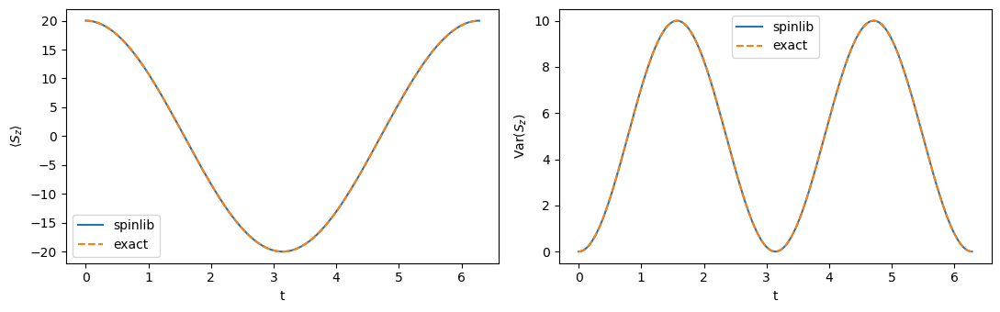

In [20]:
N, Omega = 41, 1.0                         # parameters: dimension and Rabi frequency
J = (N - 1) / 2
Sx, Sy, Sz = spin_matrices(N)
E, P = np.linalg.eigh(Omega * Sx)          # H = Omega Sx, diagonalised once
q = spinlib.Qudit(N)

# Curves: mean and variance of S_z, compared with the exact formulas.
times = np.linspace(0, 2*np.pi / Omega, 200)
mean, var = [], []
for t in times:
    q.prepareNamed("CSS+Z").evolve(E, P, t)
    mean.append(q.avgSpin()[2])
    var.append(q.covSpin()[2, 2])

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(times, mean, label="spinlib");  ax[0].plot(times, J*np.cos(Omega*times), "--", label="exact")
ax[1].plot(times, var,  label="spinlib");  ax[1].plot(times, J/2*np.sin(Omega*times)**2, "--", label="exact")
ax[0].set(xlabel="t", ylabel=r"$\langle S_z\rangle$"); ax[1].set(xlabel="t", ylabel=r"Var$(S_z)$")
for a in ax: a.legend()
plt.tight_layout(); plt.show()

# Sphere: one period.
bloch_animation(lambda t: q.prepareNamed("CSS+Z").evolve(E, P, t), np.linspace(0, 2*np.pi / Omega, 25),
                title="Rabi rotation  H = Omega Sx").show()

### 4.2 One-axis twisting $H = \chi S_z^2$
The diagonal evolution of 2.5, followed up to $\chi t = \pi/2$.
**Curves:** $\langle S_x\rangle$ against the exact $J\cos(\chi t)^{2J-1}$, and the variances: $\mathrm{Var}(S_y)$
grows (anti-squeezing), $\mathrm{Var}(S_z)$ stays $J/2$ because $S_z$ commutes with $H$.
**Sphere:** the spot of CSS+X shears into an ellipse, wraps around the equator and, at $\chi t = \pi/2$, becomes a
**cat state**: two opposite spots (for this $N$, along $\pm x$; rotate the sphere to see the second one).

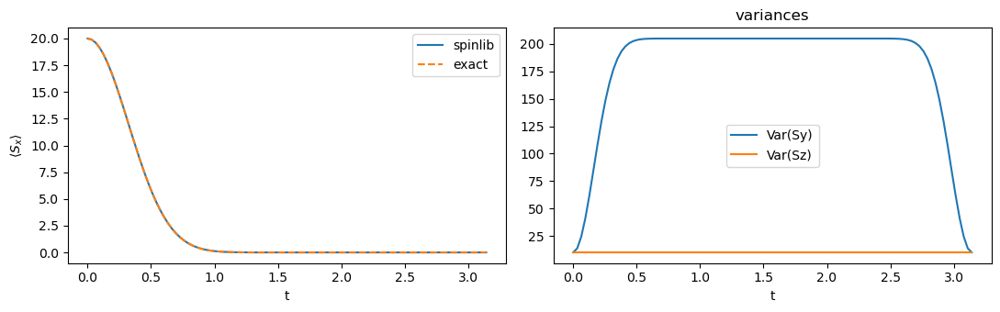

In [21]:
N, chi = 41, 0.5                                             # parameters
J = (N - 1) / 2
q = spinlib.Qudit(N)
E_oat = chi * np.array([q.spinM(k)**2 for k in range(N)])    # H = chi Sz^2 is diagonal: E_k = chi m^2
t_cat = np.pi / (2*chi)                                      # time of the cat state

# Curves.
times = np.linspace(0, t_cat, 100)
data = {key: [] for key in ["Sx", "VarSy", "VarSz"]}
for t in times:
    q.prepareNamed("CSS+X").evolveDiagonal(E_oat, t)
    C = q.covSpin()
    data["Sx"].append(q.avgSpin()[0]); data["VarSy"].append(C[1, 1]); data["VarSz"].append(C[2, 2])

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(times, data["Sx"], label="spinlib"); ax[0].plot(times, J*np.cos(chi*times)**(2*J - 1), "--", label="exact")
ax[1].plot(times, data["VarSy"], label="Var(Sy)"); ax[1].plot(times, data["VarSz"], label="Var(Sz)")
ax[0].set(xlabel="t", ylabel=r"$\langle S_x\rangle$"); ax[1].set(xlabel="t", title="variances")
for a in ax: a.legend()
plt.tight_layout(); plt.show()

# Sphere: from CSS+X to the cat state.
bloch_animation(lambda t: q.prepareNamed("CSS+X").evolveDiagonal(E_oat, t), np.linspace(0, t_cat, 31),
                title="one-axis twisting  H = chi Sz^2").show()

### 4.3 Twisting and turning $H = \chi S_z^2 + \Omega S_x$
A genuinely non-diagonal Hamiltonian with no simple closed form: the twisting term $\chi S_z^2$ shears the
fluctuations, the transverse field $\Omega S_x$ rotates them.

Starting from CSS+X, the mean spin stays along $x$ (both $H$ and the initial state are symmetric under a
$\pi$ rotation about $x$), while the fluctuations in the $y$–$z$ plane are reshaped. To quantify this:

* $\mathrm{Var}_{\min}$: the **smallest variance in the $y$–$z$ plane**, i.e. of $S_y\cos\alpha + S_z\sin\alpha$
  minimised over $\alpha$. It is the smallest eigenvalue of the $2\times2$ covariance matrix of $(S_y, S_z)$,
  i.e. of the lower-right block `C[1:, 1:]` of `C = q.covSpin()`.
* the **Wineland squeezing parameter** $\xi^2 = 2J\,\mathrm{Var}_{\min}/\langle S_x\rangle^2$, which is $1$ for a
  coherent state; $\xi^2 < 1$ means **spin squeezing** (improved precision in Ramsey interferometry).

**Sphere:** the state is squeezed quickly (the minimum of $\xi^2$), and then spreads over the sphere.
Try changing $\chi$ and $\Omega$: for $\Omega = 0$ you get back pure one-axis twisting.

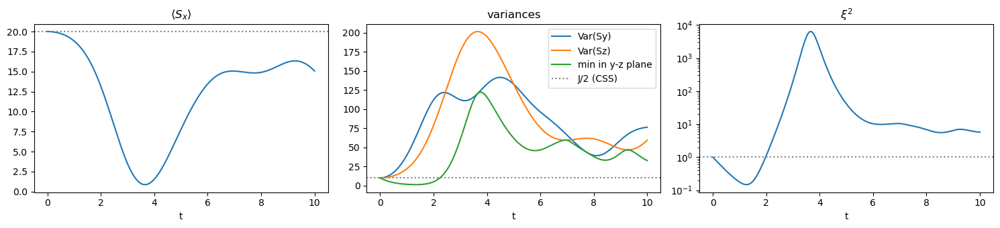

best squeezing: xi^2 = 0.1477 at t = 1.271


In [22]:
N, chi, Omega, t_max = 41, 0.05, 0.5, 10.0          # parameters
J = (N - 1) / 2
Sx, Sy, Sz = spin_matrices(N)
E, P = np.linalg.eigh(chi * Sz @ Sz + Omega * Sx)   # H = chi Sz^2 + Omega Sx, diagonalised once
q = spinlib.Qudit(N)


# Curves.
times = np.linspace(0, t_max, 300)
data = {key: [] for key in ["Sx", "VarSy", "VarSz", "Vmin", "xi2"]}
for t in times:
    q.prepareNamed("CSS+X").evolve(E, P, t)
    sx, C = q.avgSpin()[0], q.covSpin()
    vmin = np.linalg.eigvalsh(C[1:, 1:])[0]           # smallest eigenvalue of the y-z block (increasing order)
    data["Sx"].append(sx)
    data["VarSy"].append(C[1, 1])
    data["VarSz"].append(C[2, 2])
    data["Vmin"].append(vmin)
    data["xi2"].append(2 * J * vmin / sx**2)

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
ax[0].plot(times, data["Sx"]); ax[0].axhline(J, color="gray", ls=":")
ax[1].plot(times, data["VarSy"], label="Var(Sy)"); ax[1].plot(times, data["VarSz"], label="Var(Sz)")
ax[1].plot(times, data["Vmin"], label="min in y-z plane"); ax[1].axhline(J/2, color="gray", ls=":", label="J/2 (CSS)")
ax[2].semilogy(times, data["xi2"]); ax[2].axhline(1, color="gray", ls=":")
ax[0].set(xlabel="t", title=r"$\langle S_x\rangle$"); ax[1].set(xlabel="t", title="variances"); ax[2].set(xlabel="t", title=r"$\xi^2$")
ax[1].legend()
plt.tight_layout(); plt.show()
best = int(np.argmin(data["xi2"]))
print(f"best squeezing: xi^2 = {data['xi2'][best]:.4f} at t = {times[best]:.3f}")

# Sphere: up to a bit after the best squeezing.
bloch_animation(lambda t: q.prepareNamed("CSS+X").evolve(E, P, t), np.linspace(0, 4, 41),
                title="twisting and turning  H = chi Sz^2 + Omega Sx").show()

### 4.4 Ramsey interferometry
The basic sequence of atomic clocks and interferometers:

1. a $\pi/2$ pulse about $y$ turns the spin from $+z$ to the equator ($+x$),
2. during a free evolution time $T$ with detuning $\delta$ the spin precesses about $z$ by the angle $\delta T$
   (`applyPulseZ(delta*T)`),
3. a second $\pi/2$ pulse about $y$ maps that angle back onto $S_z$.

**Curve:** the final population imbalance is $\langle S_z\rangle = -J\cos(\delta T)$, the **Ramsey fringes**.
**Sphere:** the state after each step, for one detuning. Only pulses are used here, no matrices.

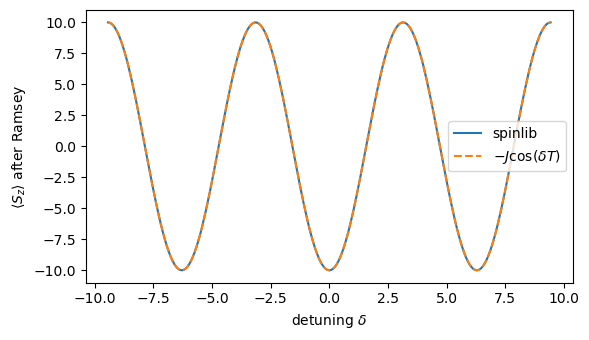

In [23]:
N, T = 21, 1.0                                       # parameters: dimension and free evolution time
J = (N - 1) / 2
q = spinlib.Qudit(N)

# Curve: <Sz> after the sequence, for many detunings.
deltas = np.linspace(-3*np.pi, 3*np.pi, 241)
sz = [q.prepareNamed("CSS+Z").applyPulseYPiHalf().applyPulseZ(d*T).applyPulseYPiHalf().avgSpin()[2] for d in deltas]

plt.figure(figsize=(6, 3.5))
plt.plot(deltas, sz, label="spinlib"); plt.plot(deltas, -J*np.cos(deltas*T), "--", label=r"$-J\cos(\delta T)$")
plt.xlabel(r"detuning $\delta$"); plt.ylabel(r"$\langle S_z\rangle$ after Ramsey"); plt.legend(); plt.tight_layout(); plt.show()

# Sphere: the three steps of the sequence for delta T = pi/3.
delta = np.pi / 3
q.prepareNamed("CSS+Z").applyPulseYPiHalf();  bloch_figure(q, "1. after the first pi/2 pulse").show()
q.applyPulseZ(delta*T);                        bloch_figure(q, "2. after the free precession, delta T = pi/3").show()
q.applyPulseYPiHalf();                         bloch_figure(q, "3. after the second pi/2 pulse").show()